In [8]:
import pandas as pd
import numpy as np
COLS = ["unit","cycle","op1","op2","op3"] + [f"s{i}" for i in range(1,22)]
train = pd.read_csv("../data/raw/train_FD001.txt", sep=r"\s+", header=None, names=COLS)
print(train.shape)

(20631, 26)


In [3]:
print("NaNs:", train.isna().sum().sum(), "| engines:", train["unit"].nunique())

sensors = [f"s{i}" for i in range(1, 22)]
std = train[sensors].std().round(4)
print(std)

keep = [s for s in sensors if std[s] > 0.01]
print(len(keep), keep)

NaNs: 0 | engines: 100
s1      0.0000
s2      0.5001
s3      6.1311
s4      9.0006
s5      0.0000
s6      0.0014
s7      0.8851
s8      0.0710
s9     22.0829
s10     0.0000
s11     0.2671
s12     0.7376
s13     0.0719
s14    19.0762
s15     0.0375
s16     0.0000
s17     1.5488
s18     0.0000
s19     0.0000
s20     0.1807
s21     0.1083
dtype: float64
14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [4]:
last = train.groupby("unit")["cycle"].transform("max")
train["rul"] = (last - train["cycle"]).clip(upper=125)

print(train[["unit", "cycle", "rul"]].head(3))
print(train[train.unit == 1][["cycle", "rul"]].tail(3))
print("max RUL:", train["rul"].max(), "| min RUL:", train["rul"].min())

   unit  cycle  rul
0     1      1  125
1     1      2  125
2     1      3  125
     cycle  rul
189    190    2
190    191    1
191    192    0
max RUL: 125 | min RUL: 0


In [5]:
lo, hi = train[keep].min(), train[keep].max()   # fit on TRAIN only

train_s = train.copy()
train_s[keep] = 2 * (train[keep] - lo) / (hi - lo) - 1

print(train_s[keep].min().round(3).to_dict())
print(train_s[keep].max().round(3).to_dict())

{'s2': -1.0, 's3': -1.0, 's4': -1.0, 's7': -1.0, 's8': -1.0, 's9': -1.0, 's11': -1.0, 's12': -1.0, 's13': -1.0, 's14': -1.0, 's15': -1.0, 's17': -1.0, 's20': -1.0, 's21': -1.0}
{'s2': 1.0, 's3': 1.0, 's4': 1.0, 's7': 1.0, 's8': 1.0, 's9': 1.0, 's11': 1.0, 's12': 1.0, 's13': 1.0, 's14': 1.0, 's15': 1.0, 's17': 1.0, 's20': 1.0, 's21': 1.0}


In [6]:
units = train["unit"].unique()
val_units = units[80:]                         # last 20 engines
tr = train[~train.unit.isin(val_units)].copy()
va = train[train.unit.isin(val_units)].copy()

# refit scaler on the 80 TRAIN engines only
lo, hi = tr[keep].min(), tr[keep].max()
tr[keep] = 2 * (tr[keep] - lo) / (hi - lo) - 1
va[keep] = 2 * (va[keep] - lo) / (hi - lo) - 1

print("train engines:", tr.unit.nunique(), "| val engines:", va.unit.nunique())
print("overlap:", set(tr.unit) & set(va.unit))
print("train range:", tr[keep].min().min(), tr[keep].max().max())
print("val range:", round(va[keep].min().min(), 3), round(va[keep].max().max(), 3))

train engines: 80 | val engines: 20
overlap: set()
train range: -1.0 1.0
val range: -1.037 1.182


In [9]:
L = 30

def windows(df, L=L):
    X, y = [], []
    for _, g in df.groupby("unit"):
        a, r = g[keep].to_numpy(np.float32), g["rul"].to_numpy(np.float32)
        for i in range(len(a) - L + 1):
            X.append(a[i:i+L]); y.append(r[i+L-1])
    return np.stack(X), np.array(y)

Xtr, ytr = windows(tr)
Xva, yva = windows(va)

# test: last L cycles of each engine, scaled with the TRAIN lo/hi
test = pd.read_csv("../data/raw/test_FD001.txt", sep=r"\s+", header=None, names=COLS)
test[keep] = 2 * (test[keep] - lo) / (hi - lo) - 1
Xte = np.stack([g[keep].to_numpy(np.float32)[-L:] for _, g in test.groupby("unit")])
yte = np.minimum(pd.read_csv("../data/raw/RUL_FD001.txt", header=None)[0].to_numpy(), 125)

print("train:", Xtr.shape, ytr.shape)
print("val:  ", Xva.shape, yva.shape)
print("test: ", Xte.shape, yte.shape)
print("total train+val windows:", len(Xtr) + len(Xva), "(expect 17731)")

train: (13818, 30, 14) (13818,)
val:   (3913, 30, 14) (3913,)
test:  (100, 30, 14) (100,)
total train+val windows: 17731 (expect 17731)


Matplotlib is building the font cache; this may take a moment.


alpha_bar[0] = 0.9999 | alpha_bar[999] = 4e-05


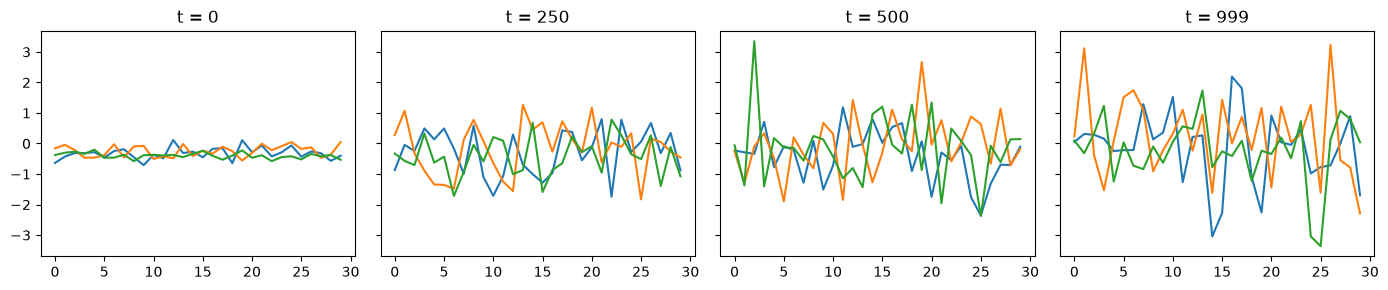

In [10]:
import matplotlib.pyplot as plt

T = 1000
beta = np.linspace(1e-4, 0.02, T, dtype=np.float32)
ab = np.cumprod(1 - beta)                      # alpha_bar

def q_sample(x0, t):
    eps = np.random.randn(*x0.shape).astype(np.float32)
    return np.sqrt(ab[t]) * x0 + np.sqrt(1 - ab[t]) * eps

print("alpha_bar[0] =", round(float(ab[0]), 4), "| alpha_bar[999] =", round(float(ab[-1]), 6))

x0 = Xtr[0]                                    # one window, shape (30, 14)
fig, axs = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, t in zip(axs, [0, 250, 500, 999]):
    ax.plot(q_sample(x0, t)[:, :3]); ax.set_title(f"t = {t}")
plt.tight_layout(); plt.show()

np.savez("../data/processed/processed_FD001.npz", Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva,
         Xte=Xte, yte=yte, lo=lo.to_numpy(), hi=hi.to_numpy())

In [ ]:
import sys; sys.path.append("../src")
import torch, numpy as np
from model import Conditioner, rul_to_bin

data = np.load("../data/processed/processed_FD001.npz")
y = torch.tensor(data["ytr"][:8])
t = torch.randint(0, 1000, (8,))

cond = Conditioner(d=64)
out = cond(t, rul_to_bin(y), drop_prob=0.1)
print(out.shape)                                  # expect torch.Size([8, 64])
print(rul_to_bin(y).tolist())                     # bins in 0..9

e = cond.t_emb(torch.tensor([0, 500]))
print("different t differs:", bool((e[0] - e[1]).abs().mean() > 0))   # expect True

torch.Size([8, 64])
[9, 9, 9, 9, 9, 9, 9, 9]
different t differs: True


In [ ]:
import importlib, sys
sys.path.insert(0, "../src")
import model
importlib.reload(model)
print(model.__file__)
print([n for n in dir(model) if n[0].isupper()])

c:\Users\Harshini\OneDrive\Desktop\MAJOR PROJECT\notebooks\../src\model.py
['ConditionEmbedding', 'Conditioner', 'DiTBlock', 'TimestepEmbedding']


In [17]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys; sys.path.append("../src")
import torch, torch.nn as nn
from model import DiTBlock

block = DiTBlock(d=64, heads=4)
x = torch.randn(8, 30, 64)       # 8 windows, 30 tokens, d=64
c = torch.randn(8, 64)           # conditioning vector from Day 2

out = block(x, c)
print(out.shape, "| identity at init:", torch.allclose(out, x))

nn.init.normal_(block.ada[1].weight, std=0.02)    # un-zero it
print("changes x after un-zeroing:", not torch.allclose(block(x, c), x))

torch.Size([8, 30, 64]) | identity at init: True
changes x after un-zeroing: True


In [ ]:
import torch, numpy as np, torch.nn.functional as F
from model import DiT, rul_to_bin

data = np.load("../data/processed/processed_FD001.npz")
x0 = torch.tensor(data["Xtr"][:32])
y  = rul_to_bin(torch.tensor(data["ytr"][:32]))

T = 1000
ab = torch.cumprod(1 - torch.linspace(1e-4, 0.02, T), 0)

# fixed t and noise, so the model can memorize this batch
t = torch.randint(0, T, (32,))
eps = torch.randn_like(x0)
a = ab[t][:, None, None]
xt = a.sqrt() * x0 + (1 - a).sqrt() * eps

model = DiT(d=64, depth=2)
print("params:", sum(p.numel() for p in model.parameters()))
print("output shape:", model(xt, t, y).shape)          # expect (32, 30, 14)

opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
for step in range(501):
    loss = F.mse_loss(model(xt, t, y), eps)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 100 == 0:
        print(step, round(loss.item(), 4))

params: 174606
output shape: torch.Size([32, 30, 14])
0 0.9972
100 0.012
200 0.0041
300 0.0015
400 0.0008
500 0.0005


In [20]:
import sys; sys.path.append("../src")
from train import train
ema, hist = train(epochs=3)

epoch   1 | train 0.5688 | val (EMA) 0.1242
epoch   2 | train 0.0730 | val (EMA) 0.0638
epoch   3 | train 0.0603 | val (EMA) 0.0600
saved ../results/dit_fd001.pt


epoch   1 | train 0.5735 | val (EMA) 0.1308
epoch   2 | train 0.0770 | val (EMA) 0.0639
epoch   3 | train 0.0602 | val (EMA) 0.0598
epoch   4 | train 0.0592 | val (EMA) 0.0585
epoch   5 | train 0.0597 | val (EMA) 0.0577
epoch   6 | train 0.0573 | val (EMA) 0.0572
epoch   7 | train 0.0587 | val (EMA) 0.0569
epoch   8 | train 0.0586 | val (EMA) 0.0566
epoch   9 | train 0.0562 | val (EMA) 0.0563
epoch  10 | train 0.0558 | val (EMA) 0.0561
epoch  11 | train 0.0546 | val (EMA) 0.0560
epoch  12 | train 0.0550 | val (EMA) 0.0558
epoch  13 | train 0.0571 | val (EMA) 0.0557
epoch  14 | train 0.0544 | val (EMA) 0.0556
epoch  15 | train 0.0576 | val (EMA) 0.0554
epoch  16 | train 0.0541 | val (EMA) 0.0553
epoch  17 | train 0.0570 | val (EMA) 0.0552
epoch  18 | train 0.0534 | val (EMA) 0.0552
epoch  19 | train 0.0565 | val (EMA) 0.0551
epoch  20 | train 0.0541 | val (EMA) 0.0551
epoch  21 | train 0.0544 | val (EMA) 0.0550
epoch  22 | train 0.0556 | val (EMA) 0.0550
epoch  23 | train 0.0556 | val (

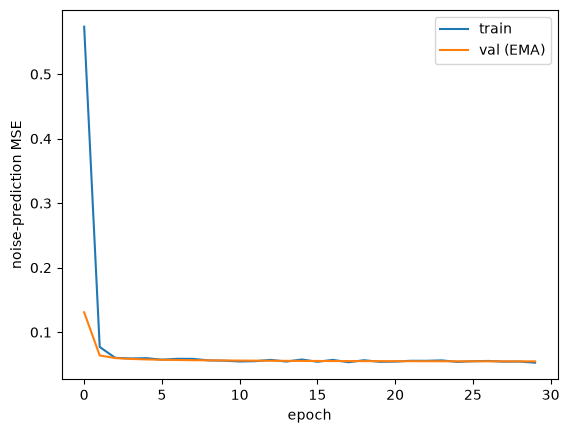

In [21]:
ema, hist = train(epochs=30)

import matplotlib.pyplot as plt
tr, va = zip(*hist)
plt.plot(tr, label="train"); plt.plot(va, label="val (EMA)")
plt.xlabel("epoch"); plt.ylabel("noise-prediction MSE"); plt.legend()
plt.savefig("../results/loss_curve.png", dpi=150); plt.show()

max mean gap: 0.008
std ratio (fake/real) min/max: 0.94 1.0
mean correlation gap: 0.042


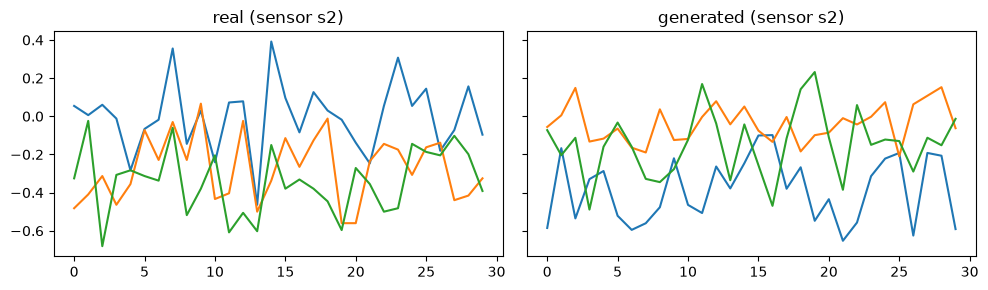

In [22]:
import sys; sys.path.append("../src")
import numpy as np, torch, matplotlib.pyplot as plt
from sample import load_ema, ddim_sample, realism_report
from diffusion import make_schedule
from model import rul_to_bin

model, cfg = load_ema()
_, ab = make_schedule(cfg["T"])

data = np.load("../data/processed/processed_FD001.npz")
idx = np.random.default_rng(0).choice(len(data["Xtr"]), 500, replace=False)
real = data["Xtr"][idx]
c = rul_to_bin(torch.tensor(data["ytr"][idx]))      # same RUL bins as the real windows

fake = ddim_sample(model, c, ab, steps=50, guidance=1.0).numpy()

mean_gap, std_ratio, corr_gap = realism_report(real, fake)
print("max mean gap:", mean_gap.max().round(3))
print("std ratio (fake/real) min/max:", std_ratio.min().round(2), std_ratio.max().round(2))
print("mean correlation gap:", corr_gap.round(3))

fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
axs[0].plot(real[:3, :, 0].T); axs[0].set_title("real (sensor s2)")
axs[1].plot(fake[:3, :, 0].T); axs[1].set_title("generated (sensor s2)")
plt.tight_layout(); plt.savefig("../results/real_vs_fake.png", dpi=150); plt.show()

In [23]:
bins = c.numpy()
j = 6   # sensor s11, which drifts strongly as engines wear out
for b in [0, 3, 6, 9]:
    m = bins == b
    if m.sum() > 5:
        print(f"bin {b}: n={m.sum():3d} | real {real[m, :, j].mean():+.3f} | fake {fake[m, :, j].mean():+.3f}")

def lag1(x):   # lag-1 autocorrelation, averaged over windows and sensors
    a = x - x.mean(1, keepdims=True)
    return ((a[:, 1:] * a[:, :-1]).sum(1) / (a ** 2).sum(1)).mean()
print("lag-1 autocorr real/fake:", lag1(real).round(3), lag1(fake).round(3))

bin 0: n= 26 | real +0.237 | fake +0.172
bin 3: n= 37 | real -0.095 | fake -0.049
bin 6: n= 32 | real -0.226 | fake -0.293
bin 9: n=194 | real -0.412 | fake -0.415
lag-1 autocorr real/fake: 0.032 0.046


In [24]:
import sys; sys.path.append("../src")
import numpy as np, torch
from sample import load_ema, ddim_sample, ddim_denoise
from diffusion import make_schedule
from model import rul_to_bin

model, cfg = load_ema()
_, ab = make_schedule(cfg["T"])
data = np.load("../data/processed/processed_FD001.npz")

# A) Can it remove noise we add ourselves? (clean ground truth exists)
x = torch.tensor(data["Xva"][:500]); y = rul_to_bin(torch.tensor(data["yva"][:500]))
noisy = x + 0.3 * torch.randn_like(x)
print("noisy -> clean MSE:", ((noisy - x) ** 2).mean().item())
for ts in [50, 100, 150]:
    den = ddim_denoise(model, noisy, y, ab, t_star=ts)
    print(f"t*={ts:3d} denoised -> clean MSE:", ((den - x) ** 2).mean().item())

# B) What does it do to the real data? (how much does it smooth?)
den = ddim_denoise(model, x, y, ab, t_star=50)
d = lambda a: (a[:, 1:] - a[:, :-1]).std().item()
print("cycle-to-cycle jitter  raw:", round(d(x), 3), "| denoised:", round(d(den), 3))

# C) Where do the augmentation windows need to go?
bins = rul_to_bin(torch.tensor(data["ytr"])).numpy()
print("windows per RUL bin:", np.bincount(bins, minlength=10))

noisy -> clean MSE: 0.09020619094371796
t*= 50 denoised -> clean MSE: 0.04632164537906647
t*=100 denoised -> clean MSE: 0.0352456271648407
t*=150 denoised -> clean MSE: 0.032412633299827576
cycle-to-cycle jitter  raw: 0.198 | denoised: 0.188
windows per RUL bin: [1040  960 1040  960 1040  960 1040  959 1017 4802]
